# 📈 Trader d'un jour

**Équipe :** *à compléter*
**Membres :** *à compléter*

Lisez d'abord les règles du jeu dans `README.md`. Tout votre travail se fait dans ce notebook, c'est lui que vous rendrez : commencez par le **renommer `groupe-N.ipynb`** (N = votre numéro de groupe).

## Le vocabulaire, pour ceux qui n'ont jamais mis les pieds en bourse

Aucune connaissance en finance n'est nécessaire. Voici les seuls mots à connaître :

- une **action** est une petite part d'une entreprise (ici Amazon) ; elle s'achète et se vend en bourse
- son **cours** est son prix ; il change en permanence pendant la journée
- le **cours de clôture** (`Close`) est le prix à la fermeture de la bourse ; c'est le seul que nous utiliserons.
  Les colonnes `Open`, `High`, `Low` sont les prix à l'ouverture, le plus haut et le plus bas de la journée ;
  `Volume` est le nombre d'actions échangées dans la journée
- on note $C_t$ le cours de clôture du jour $t$
- un **jour de cotation** est un jour où la bourse est ouverte : pas les week-ends, pas les jours fériés ;
  il y en a environ 252 par an
- votre **portefeuille**, c'est votre cash (des dollars) plus vos actions ; sa **valeur** un jour $t$ est

  $$V_t = \text{cash} + n \times C_t$$

  où $n$ est le nombre d'actions que vous détenez. C'est ce que vous auriez en poche si vous vendiez tout ce jour-là
- **acheter** $n$ actions coûte $n \times C_t$, **vendre** $n$ actions rapporte $n \times C_t$ ;
  dans les deux cas la bourse prélève des **frais** de $f = 0{,}1\,\%$ :
  vous payez $n \, C_t \, (1 + f)$ à l'achat, vous touchez $n \, C_t \, (1 - f)$ à la vente
- **être investi** = avoir ses dollars sous forme d'actions ; **être en cash** = les avoir sous forme de dollars.
  Investi, vous gagnez quand le cours monte et perdez quand il baisse ; en cash, il ne se passe rien
- une **stratégie** est la règle qui décide, chaque jour, d'acheter, de vendre, ou de ne rien faire.
  Tout le projet consiste à en trouver une bonne

In [ ]:
# ⚠️ Ne touchez pas à cette cellule : elle vérifie le nom du notebook
import os
from pathlib import Path

# ponytail: JupyterLab/Notebook 7 (JPY_SESSION_NAME) et VS Code (__vsc_ipynb_file__) ; ailleurs on ne vérifie pas
_nom = Path(globals().get("__vsc_ipynb_file__") or os.environ.get("JPY_SESSION_NAME", "")).name
if _nom == "projet.ipynb":
    raise RuntimeError(
        "\n\n" + "🛑 " * 20 +
        "\n\nCE NOTEBOOK S'APPELLE ENCORE projet.ipynb !\n"
        "Renommez-le en groupe-N.ipynb (N = votre numéro de groupe, ex. groupe-3.ipynb),\n"
        "rouvrez-le, puis relancez. Un notebook mal nommé est ignoré par git et ne sera PAS corrigé.\n\n"
        + "🛑 " * 20
    )


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from trading import Stock

## 1. Échauffement (~30 min)

Avant de jouer, on apprend à lire les cours. Chaque question de cette partie prépare un outil que vous réutiliserez dans votre stratégie.

### 1.1 Charger les cours

Le fichier `data/Amazon.csv` contient, pour chaque jour de cotation de mai 1997 à août 2020, les cours de l'action Amazon.
Il commence par 3 lignes de commentaires, et quelques dates sont manquantes.

Construisez une dataframe `df` :

- indexée par la date, de type `datetime`, sans `NaT`, triée par date croissante
- avec au moins la colonne `Close` (le cours de clôture)

Rappels utiles : `pd.read_csv(..., skiprows=)`, `pd.to_datetime()`, `dropna(subset=)`, `set_index()`, `sort_index()`.

In [18]:
# votre code
df = pd.read_csv("data/Amazon.csv", skiprows=3) # on ignore les premieres lignes qui font bugguer la lecture (des commentaires)
df['Date']=pd.to_datetime(df['Date'])
df=df.dropna(subset=['Date'])
df=df.set_index('Date') #L'index est la Date 
df=df.sort_index() #On trie par rapport à la date.


Vérifiez votre travail : les trois valeurs ci-dessous doivent être `datetime64[ns]`, `False`, `True`.

In [17]:
df.index.dtype, df.index.hasnans, df.index.is_monotonic_increasing

(dtype('<M8[us]'), False, True)

Et celle-ci vous dit ce qu'il reste de manquant. Est-ce gênant pour la suite ? (indice : quelle colonne utilise le simulateur ?)

In [ ]:
df.isna().sum()

#La colonne Volume possede des cases vides. Ce n'est pas genant parce que ce qui interesse le simulateur est le prix de l'action à la fermeture et non pas le nombre d'actions échangées

Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       8
dtype: int64

### 1.2 Explorer

**Tracez `Close` sur toute la période**, puis une seconde fois avec une échelle logarithmique (`df.Close.plot(logy=True)`).

Pourquoi le log ? Le cours est passé de 2 $ à 3000 $ : sur une échelle normale, les 15 premières années sont écrasées contre l'axe.
Sur une échelle logarithmique, **une même hausse en pourcentage occupe la même hauteur**, que le cours soit à 5 $ ou à 2000 $ :
passer de 10 à 20 $ (+100 %) a la même taille que passer de 1000 à 2000 $. C'est ce qui compte pour un investisseur, qui raisonne en pourcentage de son capital.

**Calculez le cours moyen de chaque année** avec `df.Close.resample('YE').mean()` (`'YE'` = *year end*, une ligne par année).

**Trouvez la meilleure et la pire année.** La *performance* d'une année est le gain, en proportion, de quelqu'un qui aurait acheté le premier jour de l'année et vendu le dernier :

$$\text{perf} = \frac{C_{\text{dernier jour}}}{C_{\text{premier jour}}} - 1$$

Par exemple $\text{perf} = 0{,}5$ signifie +50 %, et $-0{,}3$ signifie que l'on a perdu 30 % de sa mise.
Indice : `resample('YE').first()` et `.last()`.

Date
1997-12-31   -0.655602
1998-12-31   -0.911284
1999-12-31   -0.182266
2000-12-31    4.265060
2001-12-31    0.623152
2002-12-31   -0.370037
2003-12-31   -0.610034
2004-12-31    0.202755
2005-12-31   -0.106257
2006-12-31    0.197415
2007-12-31   -0.580095
2008-12-31    0.856669
2009-12-31   -0.598127
2010-12-31   -0.251722
2011-12-31    0.068804
2012-12-31   -0.292422
2013-12-31   -0.351839
2014-12-31    0.277396
2015-12-31   -0.552901
2016-12-31   -0.154800
2017-12-31   -0.352544
2018-12-31   -0.198253
2019-12-31   -0.188090
2020-12-31   -0.404397
Freq: YE-DEC, Name: Close, dtype: float64
La meilleure année est : 2000-12-31 00:00:00


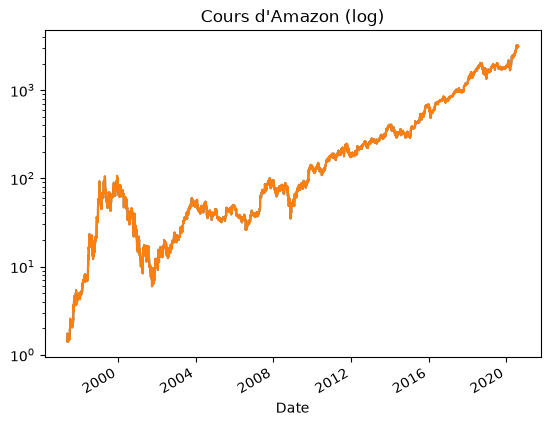

In [ ]:
# votre code
df['Close'].plot(title="Cours d'Amazon (normale)")
df['Close'].plot(logy=True,title="Cours d'Amazon (log)")
cours_moy_annuel=df['Close'].resample('YE').mean()
pj=df['Close'].resample('YE').first()
dj=df['Close'].resample('YE').last()
perf=pj/dj -1
meilleure_annee=perf.idxmax()
print(perf)
print('La meilleure année s est fini le :', meilleure_annee)  #C'est 2000 !

### 1.3 Les rendements

Le **rendement quotidien** $r_t$ est la variation du cours d'un jour sur l'autre, en proportion du cours de la veille :

$$r_t = \frac{C_t - C_{t-1}}{C_{t-1}} = \frac{C_t}{C_{t-1}} - 1$$

$r_t = 0{,}02$ veut dire que le cours a monté de 2 % ce jour-là. En pandas, c'est `df.Close.pct_change()`
(le premier jour n'a pas de veille, son rendement est `NaN`).

- **tracez l'histogramme** des rendements quotidiens (`.hist(bins=100)`) : la plupart des jours, il ne se passe presque rien ; mais regardez les extrémités
- **quel est le meilleur jour** de l'histoire d'Amazon, et le pire ? (`idxmax()`, `idxmin()` donnent la date, `max()`, `min()` la valeur). Cherchez ce qui s'est passé ces jours-là

La **volatilité** mesure à quel point le cours s'agite. C'est l'écart-type des rendements sur les $N$ derniers jours :

$$\sigma_t = \text{écart-type}\,(r_{t-N+1}, \ldots, r_t)$$

Une volatilité élevée signifie de grandes variations quotidiennes, à la hausse comme à la baisse : un marché nerveux, typique des crises.
En pandas, une **fenêtre glissante** de $N$ jours s'écrit `.rolling(N)`, donc $\sigma_t$ sur 20 jours est `df.Close.pct_change().rolling(20).std()`.

- **tracez la volatilité sur 20 jours** : repérez-vous l'éclatement de la bulle internet (2000-2002) et la crise financière (2008) ?

2001-11-26 00:00:00 2001-07-24 00:00:00


<Axes: title={'center': 'Volatilité sur 20 jours'}, xlabel='Date'>

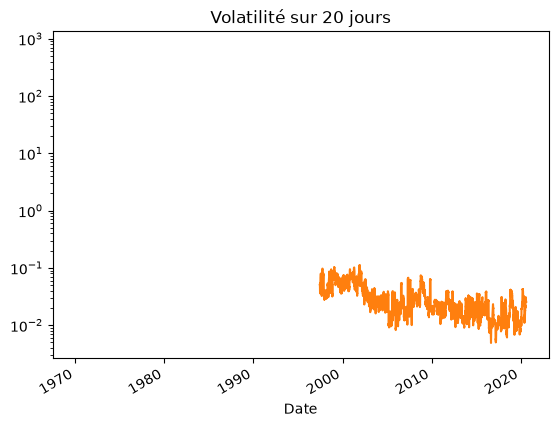

In [ ]:
# votre code
rendement=df['Close'].pct_change()
rendement.hist(bins=100)
#rendements_bis=rendement.loc['2013-01-01':]
meilleure_jour=rendement.idxmax()
pire_jour=rendement.idxmin()
print(meilleure_jour, pire_jour) 
# Le 26 novembre 2001= éclatement de la bulle technologique : -80% de la capitalisation perdue
# Le 24 juillet 2001 = 
volatilite=rendement.rolling(20).std()
volatilite.plot(logy=True,title="Volatilité sur 20 jours") #c'est ecrasé sans le log ducoup on a mis logy=True



### 1.4 Les moyennes mobiles

Le cours monte et descend tous les jours, difficile d'y voir une tendance. La **moyenne mobile** sur $N$ jours lisse ces secousses :
chaque jour, c'est la moyenne des $N$ derniers cours de clôture

$$MM_N(t) = \frac{1}{N} \sum_{k=0}^{N-1} C_{t-k} = \frac{C_t + C_{t-1} + \cdots + C_{t-N+1}}{N}$$

En pandas : `df.Close.rolling(N).mean()` (les $N-1$ premiers jours valent `NaN`, faute d'assez de passé).

Une moyenne **courte** (20 jours ≈ un mois de cotation) suit le cours de près ; une moyenne **longue** (100 jours ≈ 5 mois) ne bouge que si la tendance de fond change.
Quand la courte passe **au-dessus** de la longue, c'est que les cours récents sont plus hauts que ceux des derniers mois : le cours est en train de monter.
Quand elle passe **en dessous**, il est en train de baisser. Les traders appellent ces croisements *golden cross* et *death cross*.

- **tracez le cours et ses moyennes mobiles** sur 20 et 100 jours, restreint à 2010-2015 (`.loc['2010':'2015']`) pour que ce soit lisible
- vérifiez sur la figure ce qui se passe après chaque croisement
- **combien de fois se croisent-elles** sur cette période ? Indice : `(courte > longue)` est une série de booléens ;
  `.astype(int).diff()` vaut $+1$ ou $-1$ le jour d'un croisement, $0$ sinon

Il y a :  19.0 croisements


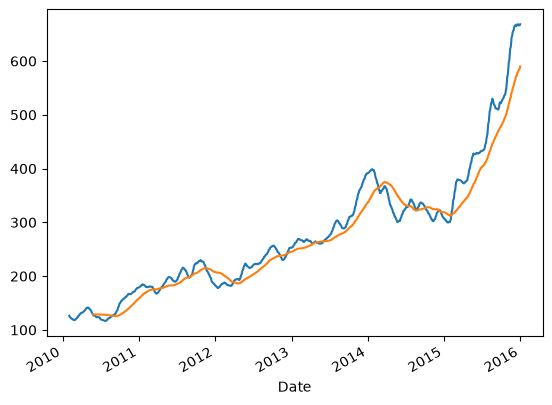

In [ ]:
# votre code
periode=df.loc['2010':'2015']
moyenne_courte=periode.Close.rolling(20).mean()
moyenne_longue=periode.Close.rolling(100).mean()
moyenne_courte.plot()
moyenne_longue.plot()
croisements=(moyenne_courte > moyenne_longue).astype(int).diff().abs() #Comme il ya des -1 et des 1 il faut prendre en valeur absolue
nbre_de_croisements=croisements.sum() #On compte le nombre de croisements en sommant les 1. 
print("Il y a : ", nbre_de_croisements, "croisements") #Il y a 19 croisement entre 2010 et 2015 

## 2. Le simulateur

`trading.py` fournit une classe `Stock` qui simule votre portefeuille jour après jour : il part de 1000 $ et 0 action,
puis rejoue l'histoire un jour de cotation à la fois. À chaque jour, votre code reçoit les cours **passés**
(jamais les futurs) et décide d'acheter, de vendre, ou d'attendre.

| méthode | rôle |
|---|---|
| `Stock(df, start=None, end=None)` | un portefeuille de 1000 $, sur les cours de `df` entre `start` et `end` |
| `stock.days()` | itère sur les jours : la date, et les cours jusqu'à ce jour inclus |
| `stock.buy(n=None)` | achète `n` actions au cours du jour (fractions autorisées) ; sans argument, dépense tout le cash |
| `stock.sell(n=None)` | vend `n` actions ; sans argument, vend tout |
| `stock.amount()` | le nombre d'actions détenues, $n$ |
| `stock.bankAccount()` | le cash disponible en $ |
| `stock.price()` | le cours de clôture du jour, $C_t$ |
| `stock.value()` | la valeur du portefeuille, $V_t = \text{cash} + n \, C_t$ |
| `stock.history()` | la valeur du portefeuille jour par jour, une fois la boucle terminée |
| `stock.plot()` | trace votre portefeuille face au buy & hold et affiche les valeurs finales |

Les frais de 0,1 % sont prélevés automatiquement à chaque `buy` et `sell`.
Acheter sans assez de cash, ou vendre plus d'actions qu'on en a, lève une `ValueError` : votre stratégie doit s'en prémunir
(d'où les `stock.bankAccount() > 0` et `stock.amount() > 0` dans l'exemple).

**Le buy & hold** (« acheter et garder ») est la stratégie de référence : tout acheter le premier jour, ne plus rien faire.
Sa valeur un jour $t$ est simplement proportionnelle au cours : $V_t = 1000 \times C_t / C_0$ (aux frais près).
`stock.plot()` la trace en même temps que vous : **c'est elle qu'il faut battre**.

Faites tourner l'exemple ci-dessous. Sa règle est simple : acheter quand l'action vaut moins de 50 $, vendre quand elle vaut plus de 100 $.

In [ ]:
stock = Stock(df, end='2015')          # 1000 $, 0 action
for date, history in stock.days():     # un tour de boucle par jour de cotation
    p = history.Close                  # les cours jusqu'à aujourd'hui inclus
    if p.iloc[-1] < 50 and stock.bankAccount() > 0:
        stock.buy()                    # tout ce qu'on peut acheter
    elif p.iloc[-1] > 100 and stock.amount() > 0:
        stock.sell()                   # tout vendre
stock.plot()

Il bat largement le buy & hold. Regardez la figure : quand a-t-il vendu, quand a-t-il racheté ?

Faites-le maintenant tourner sur `Stock(df, '2016', '2020')` : que se passe-t-il, et pourquoi ?
Répondez en une phrase ci-dessous, et méditez là-dessus avant d'écrire votre stratégie :
une règle qui marche sur le passé ne marche pas forcément sur l'avenir.

In [ ]:
# votre code


*votre réponse ici*

## 3. Votre stratégie (~1h)

Quelques pistes, à combiner, à paramétrer, ou à ignorer. Dans la boucle, `history` est la dataframe des cours jusqu'à aujourd'hui,
donc `history.Close.iloc[-1]` est $C_t$, `history.Close.iloc[-2]` est $C_{t-1}$, et tous les outils de l'échauffement
(`pct_change`, `rolling`) s'appliquent à `history.Close`.

- **croisement de moyennes mobiles** (vu en 1.4) : acheter quand $MM_{20}$ passe au-dessus de $MM_{100}$, vendre quand elle repasse dessous.
  Vous n'avez besoin que des dernières valeurs : `history.Close.rolling(20).mean().iloc[-1]`
- **acheter la baisse** : un jour de baisse est un jour où $r_t < 0$. Acheter après $N$ jours consécutifs de baisse (en pariant que ça va remonter),
  vendre après $N$ jours consécutifs de hausse
- **prendre ses gains / limiter ses pertes** : notez le cours $C_{\text{achat}}$ au moment où vous achetez ;
  le gain depuis l'achat est $g_t = C_t / C_{\text{achat}} - 1$. Vendre si $g_t > x$ (on empoche) ou si $g_t < -y$ (*stop-loss* : on coupe les pertes avant qu'elles ne grossissent)
- **volatilité** (vue en 1.3) : rester en cash quand $\sigma_t$ dépasse un seuil (le marché est trop nerveux), investir quand il se calme
- **investir partiellement** : `buy(n)` et `sell(n)` acceptent des fractions d'action, rien n'oblige à être tout ou rien.
  Par exemple n'investir que la moitié de son cash : `stock.buy(0.5 * stock.bankAccount() / stock.price())`
- **volume** : la colonne `Volume` est le nombre d'actions échangées dans la journée ; un volume anormalement élevé
  (par rapport à sa moyenne mobile) signale que quelque chose se passe. Dans quel sens ?
- **calendrier** : y a-t-il un jour de la semaine, un mois, où il vaut mieux acheter ? (`history.index.dayofweek`, `history.index.month`)

Conseils :

- les premiers jours, `history` est court : $MM_{100}$ vaut `NaN` pendant 99 jours, et un `if NaN > 3:` est toujours faux.
  Votre stratégie ne doit pas planter pour autant : testez `len(history)` ou `pd.isna(...)`
- une stratégie qui marche sur une période ne marche pas forcément sur une autre (relisez votre réponse en 2.).
  Testez sur plusieurs sous-périodes : `Stock(df, '2000', '2003')` (éclatement de la bulle internet, le cours est divisé par plus de 10),
  `Stock(df, '2008', '2010')` (crise financière), `Stock(df, '2010', '2015')` (hausse régulière).
  Une stratégie qui ne gagne que sur l'une d'elles a de bonnes chances de perdre sur la période secrète : c'est le **surapprentissage**
- comparez vos variantes dans une dataframe : une ligne par variante, une colonne par sous-période, la valeur finale dans les cases
- n'oubliez pas les frais : une stratégie qui achète et revend tous les jours perd $0{,}2\,\%$ par jour,
  soit $1 - 0{,}998^{252} \approx 40\,\%$ par an, avant même d'avoir gagné ou perdu quoi que ce soit sur le cours

Utilisez les cellules ci-dessous comme brouillon, ajoutez-en autant que vous voulez.

In [ ]:
# vos essais


In [ ]:
# vos essais


## 4. Le rendu

Votre stratégie finale dans la cellule ci-dessous, **et nulle part ailleurs** : elle ne doit dépendre que de `df` et de `trading`.
Seule la première ligne sera modifiée pour la faire tourner sur la période secrète.

Si vous définissez des fonctions ou des constantes, mettez-les dans cette même cellule.

In [ ]:
stock = Stock(df, end='2015')     # ← la seule ligne qui sera modifiée pour la période secrète
for date, history in stock.days():
    ...                           # votre stratégie
stock.plot()

**Notre stratégie en trois phrases** (pourquoi elle devrait marcher, et sur quelle période elle a échoué) :

*à compléter*